# Data Wrangling Karhutla 2026 — Pipeline Multisumber Spasial-Temporal
**Mata Kuliah Data Wrangling — Semester Gasal 2026/2027** · Dosen: Dr. Belgis Ainatul Iza, S.Si., M.Mat

| Nama | NIM | Kelas |  |
|---|---|---|---|
| Ghita Natasha Putri | 25031554023 | INT25 | |
| Sabrina Matrza Aulia | 25031554194 | INT25 | |
| Lady Puspa Khansa Yuasa | 25031554173 | INT25 | |

Sumber data: **NASA FIRMS** (hotspot) · **CHIRPS** (hujan) · **ERA5-Land** (meteorologi) · **geoBoundaries** (batas provinsi).
Alur: Ingestion → Profiling → Cleaning → Integrasi → Outlier → Scaling → Feature Engineering → Korelasi → Clean Dataset → Klasifikasi.

> Kode tiap tahap ada di `scripts/pipeline/sNN_*.py`. Notebook ini memanggilnya langkah demi langkah, menampilkan hasil,
> dan menjadi tempat menulis **keputusan + alasan** (kotak *ISI*).

In [21]:
import os, sys
from pathlib import Path
import pandas as pd
from IPython.display import Image, display, Markdown

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "scripts" / "pipeline").exists())
sys.path.insert(0, str(ROOT / "scripts"))

from pipeline import config as C
from pipeline.utils import QC
from pipeline import (s01_ingest, s02_profiling, s03_cleaning, s04_integration, s05_outliers,
                      s06_scaling, s07_features, s08_eda_corr, s09_export, s10_classification)

# "real" = data asli di data/raw_sample/  |  "demo" = data SINTETIS untuk uji coba (jangan dikumpulkan!)
MODE = os.environ.get("WRANGLING_MODE", "real")
if MODE == "demo":
    from make_demo_data import generate
    generate()
    display(Markdown("## ⚠️ MODE DEMO — data sintetis, hanya uji coba. Ganti MODE = 'real' untuk hasil asli."))
C.set_mode(MODE)
qc = QC()
pd.set_option("display.max_columns", 40, "display.width", 200)
def show(name): display(Image(filename=str(C.P.figures / name)))
print("Mode:", MODE, "| data mentah:", C.P.raw)

Mode: real | data mentah: D:\PROJECT\uas_data_wrangling\data\raw_sample


## Tahap 1 — Data Acquisition & Ingestion
Membaca data mentah dari beberapa sumber (CSV FIRMS, CSV ekspor GEE untuk CHIRPS & ERA5-Land, batas wilayah/grid)
**tanpa mengubah isinya**, lalu mencatat asal & SHA-256 tiap file (*data provenance*).

In [22]:
raw = s01_ingest.run(qc)
for k in ("firms", "chirps", "era5", "grid"):
    print(f"\n== {k}: {raw[k].shape}")
    display(raw[k].head(3))
pd.DataFrame(raw["provenance"]).drop(columns="abs_path").assign(size_mb=lambda d: (d.size_bytes/1e6).round(2)).drop(columns="size_bytes").head(10)

06:11:48 | FIRMS dibaca: firms_raw.csv (2613261 baris, 20 kolom)
06:11:48 | grid dibaca dari grid.csv
06:11:49 | GEE dibaca: gee26_20260101_20260115_jambi_c00000_bd6eb0.csv (27608 baris) | CHIRPS=True ERA5=['t2m_k', 'd2m_k', 'soil_moist', 'u10', 'v10']
06:11:49 | GEE dibaca: gee26_20260101_20260115_kalimantan_barat_c00000_65a95b.csv (82516 baris) | CHIRPS=True ERA5=['t2m_k', 'd2m_k', 'soil_moist', 'u10', 'v10']
06:11:49 | GEE dibaca: gee26_20260101_20260115_kalimantan_selatan_c00000_f63bd6.csv (21042 baris) | CHIRPS=True ERA5=['t2m_k', 'd2m_k', 'soil_moist', 'u10', 'v10']
06:11:49 | GEE dibaca: gee26_20260101_20260115_kalimantan_tengah_c00000_deff48.csv (86254 baris) | CHIRPS=True ERA5=['t2m_k', 'd2m_k', 'soil_moist', 'u10', 'v10']
06:11:49 | GEE dibaca: gee26_20260101_20260115_riau_c00000_757a06.csv (50274 baris) | CHIRPS=True ERA5=['t2m_k', 'd2m_k', 'soil_moist', 'u10', 'v10']
06:11:49 | GEE dibaca: gee26_20260101_20260115_sumatera_selatan_c00000_167195.csv (48048 baris) | CHIRPS=Tru


== firms: (2613261, 20)


,latitude,longitude,bright_ti4,scan,track,acq_date,acq_time,satellite,instrument,confidence,version,bright_ti5,frp,daynight,type,source,brightness,bright_t31,is_nrt,source_file
0,-4.84506,105.76340,329.16,0.45,0.39,2018-01-01,636,N,VIIRS,n,2,277.77,3.82,D,0.0,VIIRS_SNPP_SP,NaN,NaN,False,firms_raw.csv
1,-2.69765,105.94163,331.95,0.48,0.40,2018-01-01,636,N,VIIRS,n,2,288.08,1.66,D,0.0,VIIRS_SNPP_SP,NaN,NaN,False,firms_raw.csv
2,-3.29773,104.56150,335.14,0.44,0.39,2018-01-02,617,N,VIIRS,n,2,288.76,4.76,D,0.0,VIIRS_SNPP_SP,NaN,NaN,False,firms_raw.csv



== chirps: (6156969, 4)


,cell_id,date,source_file,precip_mm
0,193806268,2026-01-01,gee26_20260101_20260115_jambi_c00000_bd6eb0.csv,26.655085
1,193906264,2026-01-01,gee26_20260101_20260115_jambi_c00000_bd6eb0.csv,17.176529
2,193906265,2026-01-01,gee26_20260101_20260115_jambi_c00000_bd6eb0.csv,17.176529



== era5: (6156969, 8)


,cell_id,date,source_file,t2m_k,d2m_k,soil_moist,u10,v10
0,193806268,2026-01-01,gee26_20260101_20260115_jambi_c00000_bd6eb0.csv,291.850824,290.359634,0.401464,0.525801,0.039447
1,193906264,2026-01-01,gee26_20260101_20260115_jambi_c00000_bd6eb0.csv,291.125645,289.797216,0.405794,0.975753,-0.415550
2,193906265,2026-01-01,gee26_20260101_20260115_jambi_c00000_bd6eb0.csv,291.125645,289.797216,0.405794,0.975753,-0.415550



== grid: (22553, 4)


,cell_id,lat,lon,province
0,189106308,-4.8825,103.8825,Sumatera Selatan
1,189106310,-4.8825,103.9725,Sumatera Selatan
2,189106311,-4.8825,104.0175,Sumatera Selatan


,source,file,sha256,size_mb
0,NASA FIRMS,firms\firms_raw.csv,810efa09a33ad3642bf9534f5ad4beffcf0ee5fd034e3b...,275.38
1,grid (DIMAS-TI),static\grid.csv,2e6875ba854309d65066469da4ce5cf8ae2ed16085bd3c...,0.95
2,geoBoundaries,boundary\geoBoundaries-IDN-ADM1-all.zip,f495a6a3b1f6c630f63de6037895b2107ac3a8e535b04f...,15.16
3,GEE (CHIRPS + ERA5-Land),gee\gee26_20260101_20260115_jambi_c00000_bd6eb...,1cb820ba23c4ce4f74b3726f3c8f9f3e5462cd58f349e1...,3.47
4,GEE (CHIRPS + ERA5-Land),gee\gee26_20260101_20260115_kalimantan_barat_c...,f921778787c6fcd498feb9c289a3b851a336fb271b4a02...,10.34
5,GEE (CHIRPS + ERA5-Land),gee\gee26_20260101_20260115_kalimantan_selatan...,0caaa3095fc629bb56a6418ed1477072f997b504c0cd0c...,2.60
6,GEE (CHIRPS + ERA5-Land),gee\gee26_20260101_20260115_kalimantan_tengah_...,bb205727059d3a1adc3a142cb0c29cedf6ae5b7e6a72f8...,10.79
7,GEE (CHIRPS + ERA5-Land),gee\gee26_20260101_20260115_riau_c00000_757a06...,5fad3c311a9085abbaf421f36efd48265c8f385c6d0fe2...,6.25
8,GEE (CHIRPS + ERA5-Land),gee\gee26_20260101_20260115_sumatera_selatan_c...,c4cb380071bf6232b9b218ade2aa8d2ebddc4a27ce9820...,6.01
9,GEE (CHIRPS + ERA5-Land),gee\gee26_20260115_20260129_jambi_c00000_bd6eb...,ae612bf21285f7db731ac708717f62d7373cd0f47429e0...,3.45


## Tahap 2 — Data Profiling & Audit Kualitas (data mentah)
Tipe data, struktur, statistik deskriptif, % missing, duplikat, rentang tanggal/koordinat, nilai di luar domain.

In [3]:
prof = s02_profiling.run(raw, qc)
display(prof["profiles"]["firms_mentah"])
display(prof["profiles"]["era5_mentah"])
prof["audit"]

06:04:43 | gambar disimpan: profil_missing_firms_mentah.png
06:04:59 | gambar disimpan: profil_missing_chirps_mentah.png
06:05:16 | gambar disimpan: profil_missing_era5_mentah.png
06:05:39 | [2_profiling] audit_mentah = ...
06:05:39 | Profiling selesai. Lihat folder D:\PROJECT\uas_data_wrangling\outputs\profiling


,column,dtype,n_missing,pct_missing,n_unique,min,q1,median,mean,q3,max,std,top_values
0,latitude,float64,0,0.000,613509,-4.89999,-2.96011,-2.17068,-1.758742,-0.60882,2.90,1.573774,NaN
1,longitude,float64,0,0.000,962761,100.00005,105.19975,110.73566,109.775356,113.83537,116.80,4.596654,NaN
2,bright_ti4,float64,240018,9.185,6858,207.38000,312.98000,333.05000,329.849585,341.46000,367.00,17.487055,NaN
3,scan,float64,0,0.000,328,0.32000,0.40000,0.45000,0.551035,0.53000,4.82,0.370955,NaN
4,track,float64,0,0.000,144,0.36000,0.38000,0.45000,0.537052,0.59000,2.00,0.237081,NaN
5,acq_date,object,0,0.000,3202,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2026-08-29 (30408); 2026-09-01 (28227); 2026-0...
6,acq_time,int64,0,0.000,940,26.00000,606.00000,649.00000,1087.955473,1756.00000,2127.00,586.676738,NaN
7,satellite,object,0,0.000,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,N20 (1025794); N (1022437); N21 (325012)
8,instrument,object,0,0.000,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,VIIRS (2373243); MODIS (240018)
9,confidence,object,0,0.000,104,NaN,NaN,NaN,NaN,NaN,NaN,NaN,n (2186978); l (100431); h (85834)


,column,dtype,n_missing,pct_missing,n_unique,min,q1,median,mean,q3,max,std,top_values
0,cell_id,int64,0,0.0,22553,189106308.0,1.944064e+08,1.972064e+08,1.972613e+08,2.002063e+08,2.055062e+08,3.479379e+06,NaN
1,date,object,0,0.0,273,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2026-01-01 (22553); 2026-01-02 (22553); 2026-0...
2,source_file,object,0,0.0,120,NaN,NaN,NaN,NaN,NaN,NaN,NaN,gee26_20260101_20260115_kalimantan_tengah_c000...
3,t2m_k,float64,0,0.0,1138780,-9999.0,2.986291e+02,2.996387e+02,1.707601e+02,3.006149e+02,3.051908e+02,1.144369e+03,NaN
4,d2m_k,float64,0,0.0,1115664,-9999.0,2.949200e+02,2.963295e+02,1.671707e+02,2.971816e+02,2.994681e+02,1.143965e+03,NaN
5,soil_moist,float64,0,0.0,527395,-9999.0,2.850647e-01,3.796177e-01,-1.246780e+02,4.205214e-01,6.041718e-01,1.111123e+03,NaN
6,u10,float64,0,0.0,1105096,-9999.0,-6.387046e-01,-1.416430e-01,-1.252362e+02,2.419930e-01,8.095714e+00,1.111060e+03,NaN
7,v10,float64,0,0.0,1195208,-9999.0,-2.688934e-01,1.699371e-01,-1.248218e+02,7.348588e-01,8.131988e+00,1.111107e+03,NaN


{'firms': {'n_rows': 2613261,
  'n_cols': 20,
  'tanggal': {'n_total': 2613261,
   'n_non_iso': 0,
   'pct_non_iso': 0.0,
   'contoh_non_iso': []},
  'koordinat_di_luar_indonesia': 0,
  'koordinat_tidak_numerik': 0,
  'frp_negatif': 0,
  'frp_missing': 0,
  'duplikat_kunci_deteksi': 0,
  'kategori_mentah': {'confidence': {'n': 2186978,
    'l': 100431,
    'h': 85834,
    '100': 23755,
    '67': 4445,
    '69': 4364,
    '66': 4350,
    '68': 4327,
    '70': 4290,
    '72': 4268,
    '65': 4253,
    '64': 4243,
    '71': 4239,
    '73': 4220,
    '63': 4199},
   'satellite': {'N20': 1025794,
    'N': 1022437,
    'N21': 325012,
    'Aqua': 151086,
    'Terra': 88932},
   'instrument': {'VIIRS': 2373243, 'MODIS': 240018},
   'daynight': {'D': 1523905, 'N': 1089356}}},
 'gee': {'chirps_rows': 6156969,
  'era5_rows': 6156969,
  'tanggal_chirps': {'n_total': 6156969,
   'n_non_iso': 0,
   'pct_non_iso': 0.0,
   'contoh_non_iso': []},
  'duplikat_cell_date_chirps': 0,
  'duplikat_cell_date_

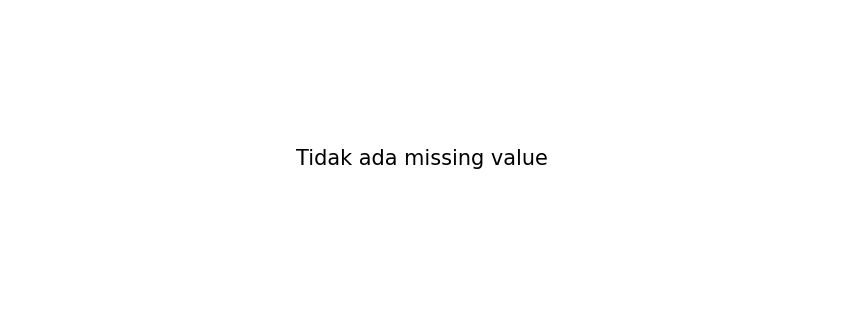

In [4]:
show("profil_missing_era5_mentah.png")

**Temuan profiling & interpretasi:** 

Audit data mentah menunjukkan kondisi yang sudah rapi: tidak ada tanggal non-ISO, koordinat di luar wilayah Indonesia, baris duplikat, maupun nilai di luar domain fisik (hujan, suhu, kelembapan relatif, kecepatan angin, kelembapan tanah). Hal ini wajar karena data mentah berasal dari penelitian DIMAS-TI yang sudah melalui pembersihan awal, sehingga kami tidak mengklaim kesalahan yang tidak ada. Temuan yang sebenarnya ada adalah:

1. **Cakupan FIRMS lebih luas dari periode proyek.** Data FIRMS mentah berisi 2.613.261 baris dan menyusut menjadi 817.096 baris setelah dibatasi pada periode proyek (Jan–Sep 2026). Rincian jumlah baris yang dibuang tercatat di `qc_report.json`.
2. **Satuan dan variabel turunan perlu diseragamkan.** Suhu diseragamkan ke °C, kecepatan angin dihitung dari komponen u/v, dan kelembapan relatif dihitung dari suhu dan titik embun (rumus Magnus).
3. **Nilai ERA5-Land kosong pada sebagian sel-hari** (307.944 nilai variabel cuaca). Penanganannya dibahas di Tahap 3.

Tabel CHIRPS dan ERA5-Land masing-masing berisi 6.156.969 baris, sama persis dengan hasil integrasi, yaitu 22.553 sel × 273 hari tanpa duplikasi kunci `cell_id + date`.

## Tahap 3 — Standardisasi & Cleaning (+ perbandingan strategi imputasi)
* tanggal → `YYYY-MM-DD`; string (satelit, confidence) di-*strip*, huruf kecil, label diseragamkan;
* Kelvin → °C, u/v angin → kecepatan angin, suhu+titik embun → RH;
* kode `-9999` dan nilai di luar domain fisik → **NaN** (bukan 0);
* duplikat dibuang tanpa menghapus deteksi hotspot berbeda (kunci: lokasi+tanggal+jam+satelit+instrumen);
* missing: **uji 6 strategi imputasi** dengan menyembunyikan nilai asli, ukur NRMSE, pilih yang terbaik *dan kausal*.

In [5]:
clean = s03_cleaning.run(raw, qc)
display(clean["missing_report"])
display(clean["imputation_table"])

06:05:51 | [3_cleaning_firms] ringkasan = ...
06:06:44 | [3_cleaning_meteo] ringkasan = ...
06:07:04 | [3_missing] baris_dengan_missing_apa_pun = 76986
06:07:04 | [3_missing] laporan = ...
06:07:06 | [3_missing] strategi_imputasi_terpilih = ffill_cell
06:07:06 | [3_missing] tabel_perbandingan = ...
06:07:06 | gambar disimpan: imputasi_perbandingan.png
06:07:11 | [3_missing] nilai_diimputasi_total = 307944
06:07:11 | [3_missing] baris_yang_punya_imputasi = 76986
06:07:11 | [3_missing] missing_tersisa = 0


,variabel,n_missing,pct_missing,sel_yang_seluruhnya_kosong
0,precip_mm,0,0.00,0
1,temp_c,76986,1.25,282
2,rh_pct,76986,1.25,282
3,wind_ms,76986,1.25,282
4,soil_moist,76986,1.25,282


,strategi,kausal,rmse_precip_mm,rmse_temp_c,rmse_rh_pct,rmse_wind_ms,rmse_soil_moist,nrmse_rata2
0,interp_cell,False,6.3474,0.5941,4.2778,0.3090,0.0119,0.4492
1,ffill_cell,True,7.5915,0.7415,5.8348,0.3884,0.0191,0.5674
2,ffill_then_province_date,True,7.5915,0.7441,5.8328,0.3884,0.0191,0.5677
3,province_date_mean,True,4.5545,1.4972,6.3857,0.8428,0.0816,0.7744
4,cell_median,True,6.2276,2.1189,19.4245,0.7765,0.1720,1.3027
5,global_mean,True,7.8479,2.4626,18.5669,1.0367,0.1742,1.4393


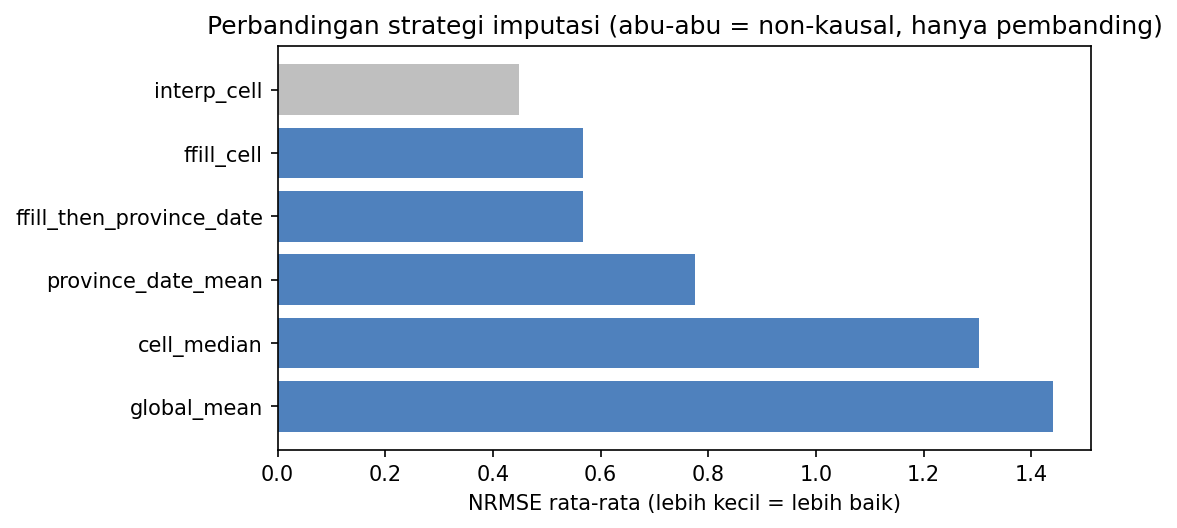

In [6]:
show("imputasi_perbandingan.png")

In [7]:
# profil SESUDAH cleaning — dibandingkan dengan profil mentah di Tahap 2
pf = s02_profiling.profile_table(clean["firms"], "firms_bersih")
pm = s02_profiling.profile_table(clean["meteo"], "meteo_bersih")
display(pf[["column", "dtype", "n_missing", "pct_missing", "n_unique"]])
display(pm[["column", "dtype", "n_missing", "pct_missing", "min", "max"]])

,column,dtype,n_missing,pct_missing,n_unique
0,lat,float64,0,0.000,365554
1,lon,float64,0,0.000,477718
2,acq_date,datetime64[ns],0,0.000,273
3,acq_time,string,0,0.000,610
4,frp,float64,0,0.000,13156
5,confidence,string,0,0.000,3
6,satellite,string,0,0.000,5
7,instrument,string,0,0.000,2
8,daynight,string,0,0.000,2
9,brightness,float64,755001,92.401,5767


,column,dtype,n_missing,pct_missing,min,max
0,cell_id,object,0,0.0,NaN,NaN
1,date,datetime64[ns],0,0.0,NaN,NaN
2,precip_mm,float32,0,0.0,0.000000,232.199356
3,temp_c,float32,0,0.0,14.940984,32.040783
4,rh_pct,float32,0,0.0,38.384094,100.000000
5,wind_ms,float32,0,0.0,0.000941,8.998363
6,soil_moist,float32,0,0.0,0.040951,0.604172
7,lat,float64,0,0.0,-4.882500,2.497500
8,lon,float64,0,0.0,100.102500,116.527500
9,province,object,0,0.0,NaN,NaN


**Keputusan missing values & alasan:** 

Nilai cuaca yang kosong tidak diisi 0 (karena 0 berarti "tidak ada hujan"/"nol derajat", bukan "tidak diketahui"), melainkan diimputasi setelah membandingkan enam strategi. Perbandingan dilakukan dengan menyembunyikan 5% nilai asli di periode validasi/uji, mengisinya dengan tiap strategi, lalu mengukur galat (NRMSE = RMSE dibagi simpangan baku nilai asli).

| Strategi | Kausal | NRMSE rata-rata |
|---|---|---|
| interpolasi linier per sel | tidak | 0,449 |
| **forward-fill per sel (maks. 3 hari)** | **ya** | **0,567** |
| forward-fill lalu rata-rata provinsi-tanggal | ya | 0,568 |
| rata-rata provinsi-tanggal | ya | 0,774 |
| median per sel | ya | 1,303 |
| rata-rata global | ya | 1,439 |

Kami memilih **forward-fill per sel**. Interpolasi linier memang paling akurat, tetapi memakai nilai hari berikutnya sehingga membocorkan informasi masa depan ke fitur historis, jadi hanya dipakai sebagai pembanding. Seluruh statistik pengisi (rata-rata/median) dihitung dari periode latih saja agar data validasi/uji tidak memengaruhi nilai pengisi. Sebanyak 307.944 nilai diimputasi dan setiap baris diberi penanda `n_imputed`.

**Keterbatasan:** galat rata-rata masih cukup besar (NRMSE 0,57). Untuk curah hujan, rata-rata provinsi-tanggal lebih baik (RMSE 4,55 mm dibanding 7,59 mm pada forward-fill), sedangkan suhu, kelembapan relatif, angin, dan kelembapan tanah lebih baik dengan forward-fill; memilih strategi per variabel berpotensi memperbaiki hasil. Uji penyembunyian juga mengasumsikan data hilang secara acak, padahal pada kenyataannya kekosongan bisa mengelompok pada sel atau periode tertentu.

## Tahap 4 — Integrasi Spasial-Temporal
Kunci **`cell_id + date`**: satu baris = satu sel grid pada satu tanggal. FIRMS dipetakan ke sel terdekat (KD-Tree),
diagregasi, lalu di-*left join* ke tabel cuaca dengan `validate="one_to_one"` agar penggandaan baris tidak mungkin lolos.

In [8]:
integ = s04_integration.run(clean, raw, qc)
print(integ.shape)
display(integ.head())
display(pd.Series(qc.data["stages"]["4_integration"]).to_frame("nilai"))

06:07:49 | [4_integration] deteksi_firms_di_luar_grid_dibuang = 67787
06:07:49 | [4_integration] deteksi_firms_dipetakan = 749309
06:07:49 | [4_integration] pasangan_cell_date_dengan_hotspot = 111982
06:07:52 | [4_integration] pasangan_hotspot_tanpa_data_cuaca = 0
06:07:52 | [4_integration] deteksi_hilang_karena_tanpa_cuaca = 0
06:07:57 | [4_integration] baris_sebelum_join = 6156969
06:07:57 | [4_integration] baris_sesudah_join = 6156969
06:07:57 | [4_integration] duplikasi_cell_date = 0
06:07:58 | [4_integration] jumlah_sel = 22553
06:07:58 | [4_integration] rentang_tanggal = ...
06:07:58 | [4_integration] persen_baris_ada_hotspot = 1.819


(6156969, 16)


,cell_id,date,precip_mm,temp_c,rh_pct,wind_ms,soil_moist,lat,lon,province,n_imputed,hotspot_count,frp_sum,frp_max,n_high_conf,n_nominal_high
0,189106308,2026-01-01,22.144737,21.116350,90.903999,0.980231,0.376616,-4.8825,103.8825,Sumatera Selatan,0,0,0.0,0.0,0,0
1,189106308,2026-01-02,17.168169,20.018864,93.913246,1.460495,0.381475,-4.8825,103.8825,Sumatera Selatan,0,0,0.0,0.0,0,0
2,189106308,2026-01-03,11.801988,20.178835,96.101509,0.730257,0.376736,-4.8825,103.8825,Sumatera Selatan,0,0,0.0,0.0,0,0
3,189106308,2026-01-04,4.170655,22.128542,83.188507,0.799068,0.364567,-4.8825,103.8825,Sumatera Selatan,0,0,0.0,0.0,0,0
4,189106308,2026-01-05,6.686131,22.256987,82.054253,0.774384,0.358959,-4.8825,103.8825,Sumatera Selatan,0,0,0.0,0.0,0,0


,nilai
deteksi_firms_di_luar_grid_dibuang,67787
deteksi_firms_dipetakan,749309
pasangan_cell_date_dengan_hotspot,111982
pasangan_hotspot_tanpa_data_cuaca,0
deteksi_hilang_karena_tanpa_cuaca,0
baris_sebelum_join,6156969
baris_sesudah_join,6156969
duplikasi_cell_date,0
jumlah_sel,22553
rentang_tanggal,"[2026-01-01, 2026-09-30]"


## Tahap 5 — Deteksi & Penanganan Outlier
IQR (univariat, pada nilai >0 untuk variabel zero-inflated) + Isolation Forest (multivariat). Dibandingkan 3 opsi
perlakuan: pertahankan / potong (cap) / buang.

In [9]:
flagged, iqr_tab = s05_outliers.run(integ, qc)
display(iqr_tab[["variabel", "dasar_hitung", "batas_bawah", "batas_atas", "n_outlier", "pct_outlier", "max", "keputusan"]])
display(pd.read_csv(C.P.tables / "outlier_perbandingan_perlakuan.csv").round(3))

06:08:08 | [5_outlier] iqr = ...
06:08:14 | gambar disimpan: outlier_distribusi.png
06:08:47 | [5_outlier] isolation_forest_n_anomali = 30828
06:08:47 | [5_outlier] isolation_forest_pct = 0.501
06:08:47 | [5_outlier] baris_setelah_perlakuan = 6156969


,variabel,dasar_hitung,batas_bawah,batas_atas,n_outlier,pct_outlier,max,keputusan
0,precip_mm,nilai > 0,-15.078444,28.080926,279003,6.430,232.199356,keep_flag
1,temp_c,semua baris,22.662929,30.346011,262966,4.271,32.040783,keep_flag
2,rh_pct,semua baris,56.868507,107.547462,165379,2.686,100.000000,keep_flag
3,wind_ms,semua baris,-1.154437,3.003732,197516,3.208,8.998363,keep_flag
4,soil_moist,semua baris,0.096182,0.615125,137135,2.227,0.604172,keep_flag
5,frp_sum,nilai > 0,-52.481251,99.628752,14200,12.681,17174.720703,keep_flag


,variabel,opsi,n,mean,std,skew,max
0,precip_mm,keep,6156969,6.029,9.926,2.693,232.199
1,precip_mm,cap,6156969,5.506,7.972,1.626,28.081
2,precip_mm,remove,5877966,4.434,6.421,1.703,28.081
3,temp_c,keep,6156969,26.377,1.775,-0.865,32.041
4,temp_c,cap,6156969,26.428,1.606,-0.252,30.346
5,temp_c,remove,5894003,26.541,1.429,-0.075,30.346
6,rh_pct,keep,6156969,81.209,10.128,-0.961,100.000
7,rh_pct,cap,6156969,81.319,9.822,-0.817,100.000
8,rh_pct,remove,5991590,81.994,9.065,-0.750,100.000
9,wind_ms,keep,6156969,1.040,0.859,1.756,8.998


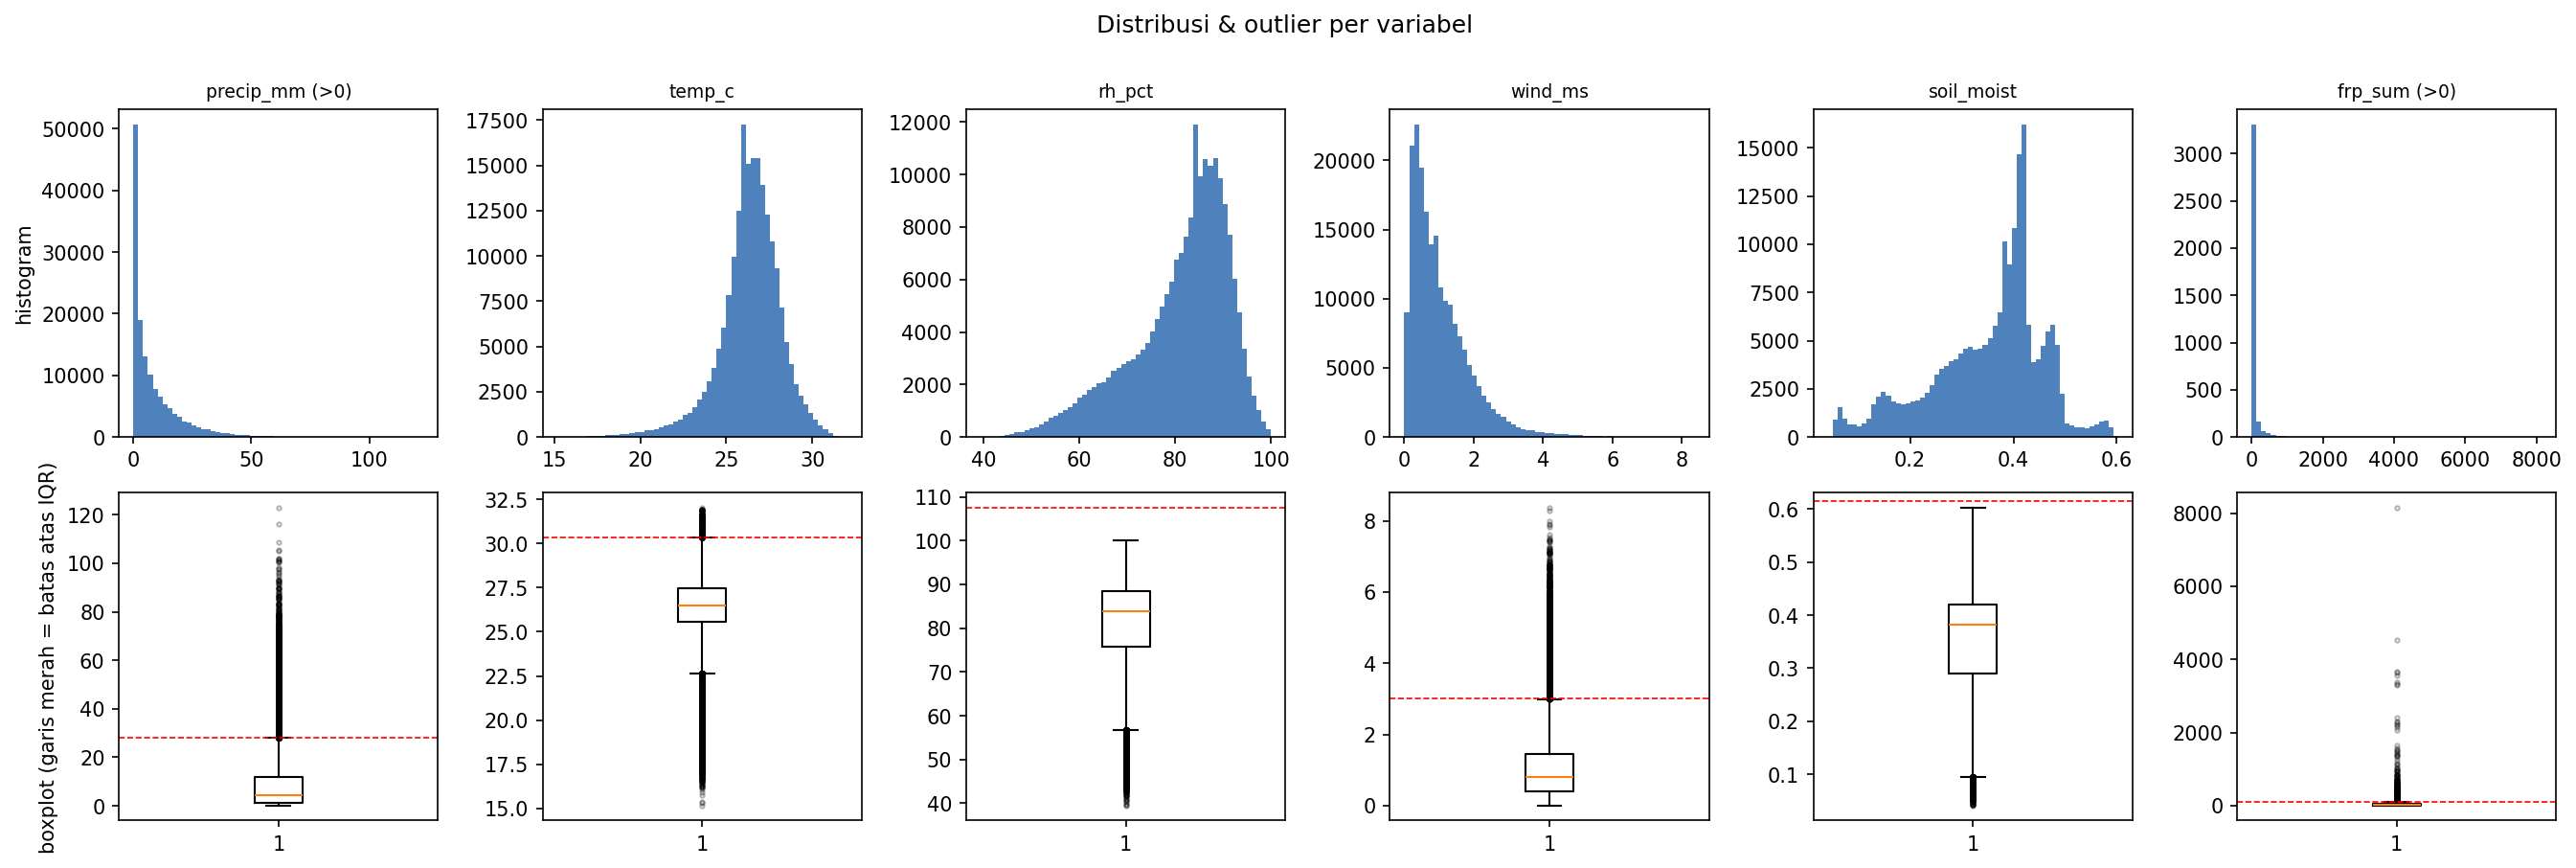

In [10]:
show("outlier_distribusi.png")

**Keputusan outlier & alasan:** 

Nilai di luar domain fisik (misalnya RH di atas 100% atau suhu mustahil) tidak ditemukan. Outlier statistik dideteksi dengan IQR (batas Q1 − 1,5·IQR dan Q3 + 1,5·IQR) dan Isolation Forest (multivariat). Untuk variabel yang banyak bernilai nol (curah hujan dan FRP), IQR dihitung hanya pada nilai > 0, karena jika tidak Q1 = Q3 = 0 dan setiap hari hujan akan salah dianggap outlier.

| Variabel | % outlier IQR | Nilai maksimum |
|---|---|---|
| curah hujan (hari hujan) | 6,43% | 232,2 mm/hari |
| suhu | 4,27% | 32,0 °C |
| kelembapan relatif | 2,69% | 100% |
| kecepatan angin | 3,21% | 9,0 m/s |
| kelembapan tanah | 2,23% | 0,604 m³/m³ |
| FRP total sel-hari | 12,68% | 17.174,7 MW |

**Keputusan: semua dipertahankan dan diberi penanda** (`out_<variabel>`), tidak dihapus atau dipotong. Nilai-nilai ekstrem ini masih masuk akal secara fisik (hujan deras, kebakaran besar) dan justru mewakili kejadian yang paling penting untuk dipelajari; menghapusnya akan membuang informasi pada kasus yang paling berarti. Catatan: batas atas IQR kelembapan relatif (107,5%) melampaui batas fisik 100%, sehingga hanya sisi bawah yang bermakna. Isolation Forest menandai 30.828 baris (0,5%) sebagai anomali multivariat; angka ini mengikuti parameter `contamination = 0,5%`, bukan temuan, sehingga dipakai hanya sebagai penanda.

## Tahap 6 — Normalisasi & Scaling
Z-score dan Min-Max, parameter dari **periode train saja**. Dataset akhir tetap satuan asli; scaling dipakai untuk
Logistic Regression, tidak untuk LightGBM.

In [11]:
sc = s06_scaling.run(flagged, qc)
display(sc["summary"].round(3))

06:08:59 | gambar disimpan: scaling_sebelum_sesudah.png
06:08:59 | [6_scaling] kolom_diskalakan = ...
06:08:59 | [6_scaling] catatan = parameter dari train saja; LightGBM tidak memakai scaling, LogReg memakai StandardScaler


,kolom,mean,std,min,max
0,precip_mm,6.029000,9.926000,0.000000,232.199005
1,precip_mm_z,-0.113000,0.938000,-0.682000,21.261999
2,precip_mm_minmax,0.026000,0.043000,0.000000,1.000000
3,temp_c,26.377001,1.775000,14.941000,32.041000
4,temp_c_z,0.258000,1.138000,-7.076000,3.891000
5,temp_c_minmax,0.751000,0.116000,0.000000,1.122000
6,rh_pct,81.209000,10.128000,38.383999,100.000000
7,rh_pct_z,-0.504000,1.482000,-6.772000,2.246000
8,rh_pct_minmax,0.610000,0.210000,-0.280000,1.000000
9,wind_ms,1.040000,0.859000,0.001000,8.998000


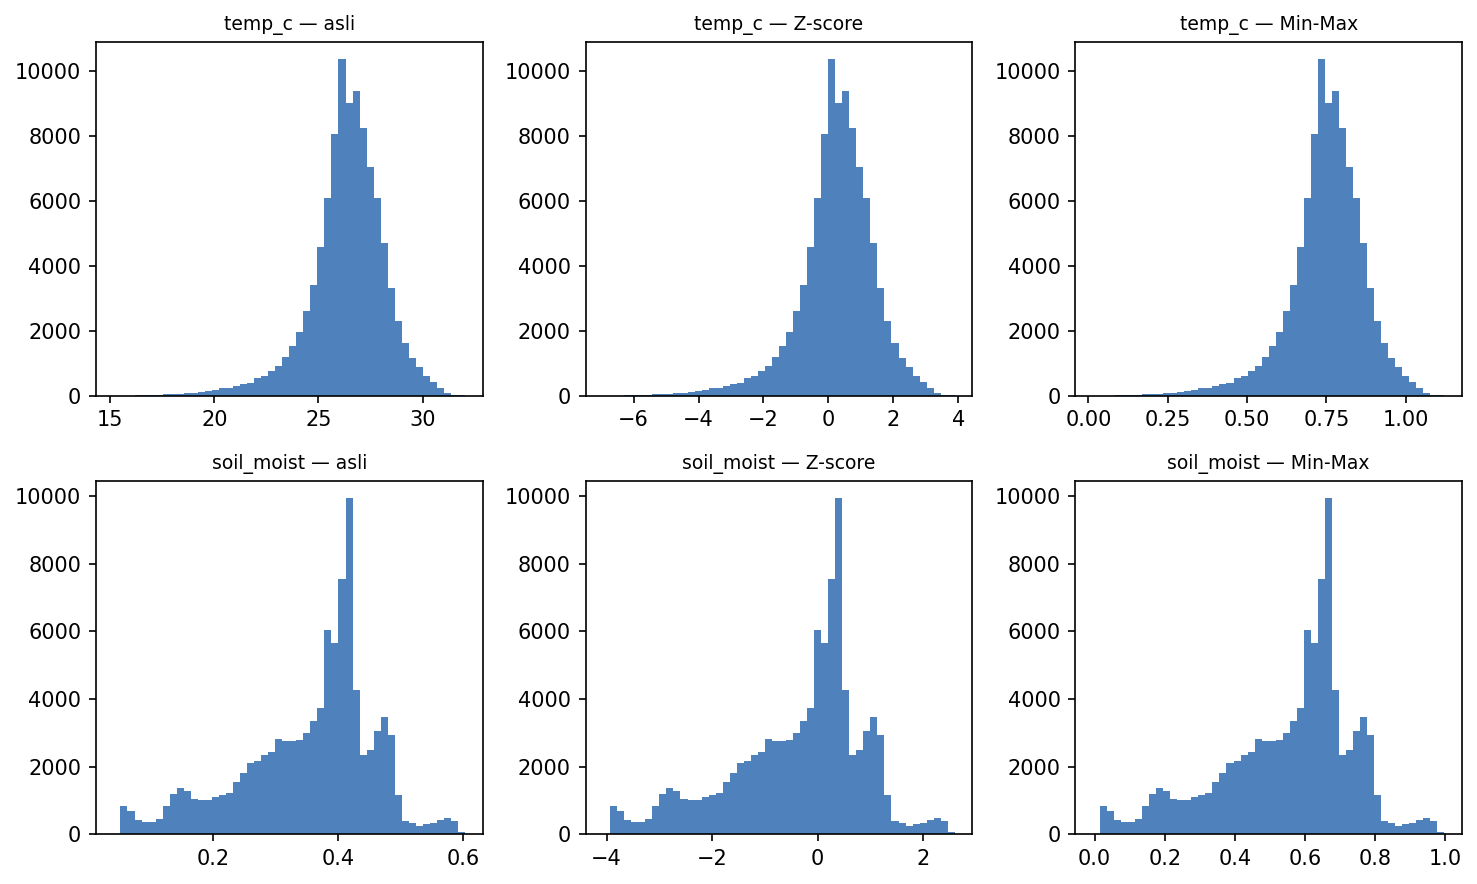

In [12]:
show("scaling_sebelum_sesudah.png")

## Tahap 7 — Feature Engineering, Reshaping, Seleksi Fitur
Fitur historis 7/14 hari **dari data sebelum tanggal t** (anti-leakage); target = ada hotspot pada t+1…t+7.
Reshaping: `pivot_table`, `melt` (unpivot), `groupby` mingguan. Seleksi: buang konstan, buang pasangan |Spearman|>0,95, peringkat Mutual Information.

In [13]:
feat = s07_features.run(flagged, qc)
df = feat["df"]
display(df[["cell_id", "date", "precip_mm", "rain_prev7_mm", "rain_prev14_mm", "hotspot_prev7", "y_hotspot_next7", "warmup"]].iloc[10:20])
print("Fitur terpilih:", feat["selected"])
display(feat["selection_table"])
display(feat["reshape"]["pivot_hotspot"])

06:09:22 | [7_features] jumlah_baris_per_split = ...
06:09:22 | [7_features] label_nominal_high_saja = False
06:09:22 | [7_features] fitur_historis = ...
06:09:22 | [7_features] baris_warmup_tanpa_fitur_lengkap = 676590
06:09:22 | [7_features] baris_tanpa_target_(7_hari_terakhir) = 157871
06:09:23 | [7_features] proporsi_kelas_positif = 0.0652
06:09:29 | gambar disimpan: pivot_hotspot_provinsi_bulan.png
06:09:29 | [7_features] reshaping = ...
06:09:39 | [7_features] fitur_kandidat = 21
06:09:39 | [7_features] fitur_terpilih = ...
06:09:39 | [7_features] fitur_dibuang = ...


,cell_id,date,precip_mm,rain_prev7_mm,rain_prev14_mm,hotspot_prev7,y_hotspot_next7,warmup
10,189106308,2026-01-11,5.870326,65.267860,NaN,0.0,0,True
11,189106308,2026-01-12,11.797384,66.967529,NaN,0.0,0,True
12,189106308,2026-01-13,8.313210,72.078789,NaN,0.0,0,True
13,189106308,2026-01-14,13.654418,78.400864,NaN,0.0,0,True
14,189106308,2026-01-15,13.357929,71.027771,156.018097,0.0,0,True
15,189106308,2026-01-16,6.278358,75.218468,147.231293,0.0,0,True
16,189106308,2026-01-17,21.971617,71.310852,136.341476,0.0,0,True
17,189106308,2026-01-18,5.933154,81.243240,146.511108,0.0,0,True
18,189106308,2026-01-19,7.784943,81.306068,148.273605,0.0,0,True
19,189106308,2026-01-20,10.678620,77.293625,149.372421,0.0,0,True


Fitur terpilih: ['precip_mm', 'temp_c', 'rh_pct', 'wind_ms', 'soil_moist', 'hotspot_count', 'dry_days_streak', 'rain_prev7_mm', 'rain_prev14_mm', 'rain_prev30_mm', 'hotspot_prev7', 'hotspot_prev14', 'temp_prev7_mean', 'rh_prev7_mean', 'soil_prev7_mean', 'wind_prev7_mean', 'lat', 'lon', 'province_code', 'month_2026']


,fitur,status,alasan,korelasi_spearman_dg_target,mutual_information
0,frp_prev7,dibuang,redundan dg hotspot_prev7 (|rho|=1.00),0.2304,NaN
1,hotspot_prev14,dipertahankan,,0.2304,0.01021
2,hotspot_prev7,dipertahankan,,0.2310,0.00875
3,month_2026,dipertahankan,,0.0848,0.00818
4,rh_pct,dipertahankan,,-0.0976,0.00617
5,dry_days_streak,dipertahankan,,0.0985,0.00584
6,hotspot_count,dipertahankan,,0.2042,0.00550
7,rh_prev7_mean,dipertahankan,,-0.0996,0.00516
8,rain_prev14_mm,dipertahankan,,-0.0914,0.00512
9,lon,dipertahankan,,-0.0091,0.00472


bulan,1,2,3,4,5,6,7,8,9
province,,,,,,,,,
Jambi,179,136,298,130,114,140,730,4881,10391
Kalimantan Barat,2261,1179,4630,335,170,381,12478,126533,83547
Kalimantan Selatan,191,54,166,168,145,241,3534,25045,31938
Kalimantan Tengah,899,126,323,153,51,183,4633,102717,219141
Riau,370,2023,3962,1347,95,151,539,5641,4159
Sumatera Selatan,161,112,331,188,356,485,2883,24850,63435


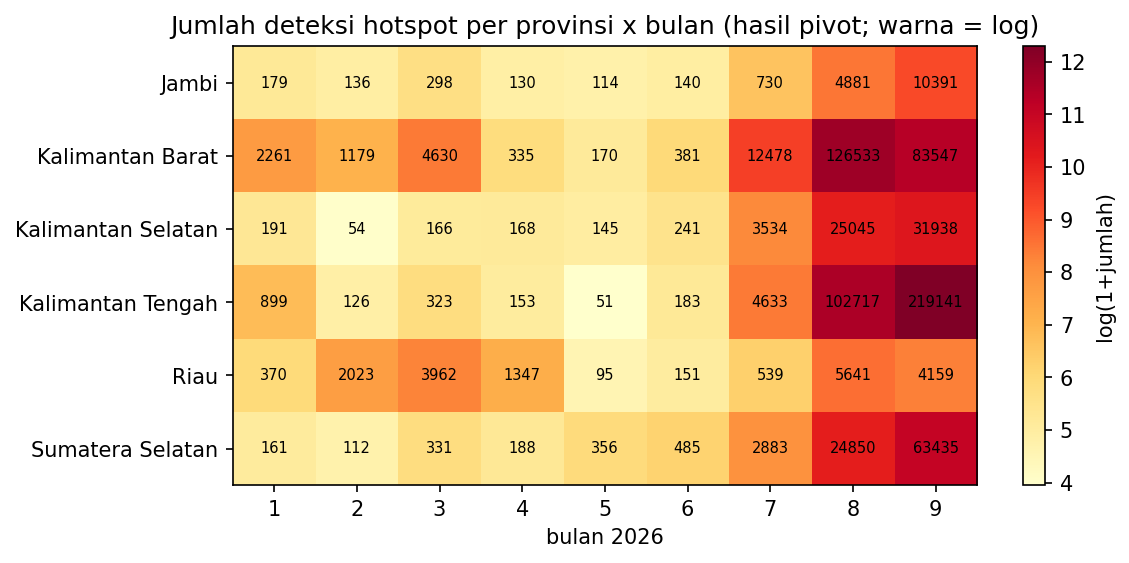

In [14]:
show("pivot_hotspot_provinsi_bulan.png")

## Tahap 8 — EDA & Analisis Korelasi
Pearson dan Spearman pada sampel acak tetap; korelasi ≠ sebab-akibat.

In [15]:
corr = s08_eda_corr.run(df, feat["selected"], qc)
display(corr["target_corr"].round(3).to_frame("spearman dg target"))
display(corr["pairs"].head(8).round(3))

06:09:58 | gambar disimpan: eda_distribusi.png
06:09:59 | gambar disimpan: eda_tren_harian.png
06:10:00 | gambar disimpan: eda_boxplot_provinsi.png
06:10:04 | gambar disimpan: heatmap_korelasi_pearson.png
06:10:10 | gambar disimpan: heatmap_korelasi_spearman.png
06:10:10 | [8_eda] korelasi_target_top5 = ...
06:10:10 | [8_eda] pasangan_terkorelasi_top3 = ...


,spearman dg target
hotspot_prev14,0.481
hotspot_prev7,0.473
hotspot_count,0.387
rh_prev7_mean,-0.278
rain_prev30_mm,-0.277
month_2026,0.272
rh_pct,-0.266
soil_prev7_mean,-0.262
soil_moist,-0.261
rain_prev14_mm,-0.260


,fitur_a,fitur_b,rho,abs_rho
83,soil_moist,soil_prev7_mean,0.942,0.942
119,rain_prev7_mm,rain_prev14_mm,0.880,0.880
132,rain_prev14_mm,rain_prev30_mm,0.862,0.862
5,precip_mm,dry_days_streak,-0.853,0.853
155,hotspot_prev7,hotspot_prev14,0.832,0.832
204,lon,province_code,-0.817,0.817
30,temp_c,temp_prev7_mean,0.812,0.812
68,wind_ms,wind_prev7_mean,0.756,0.756


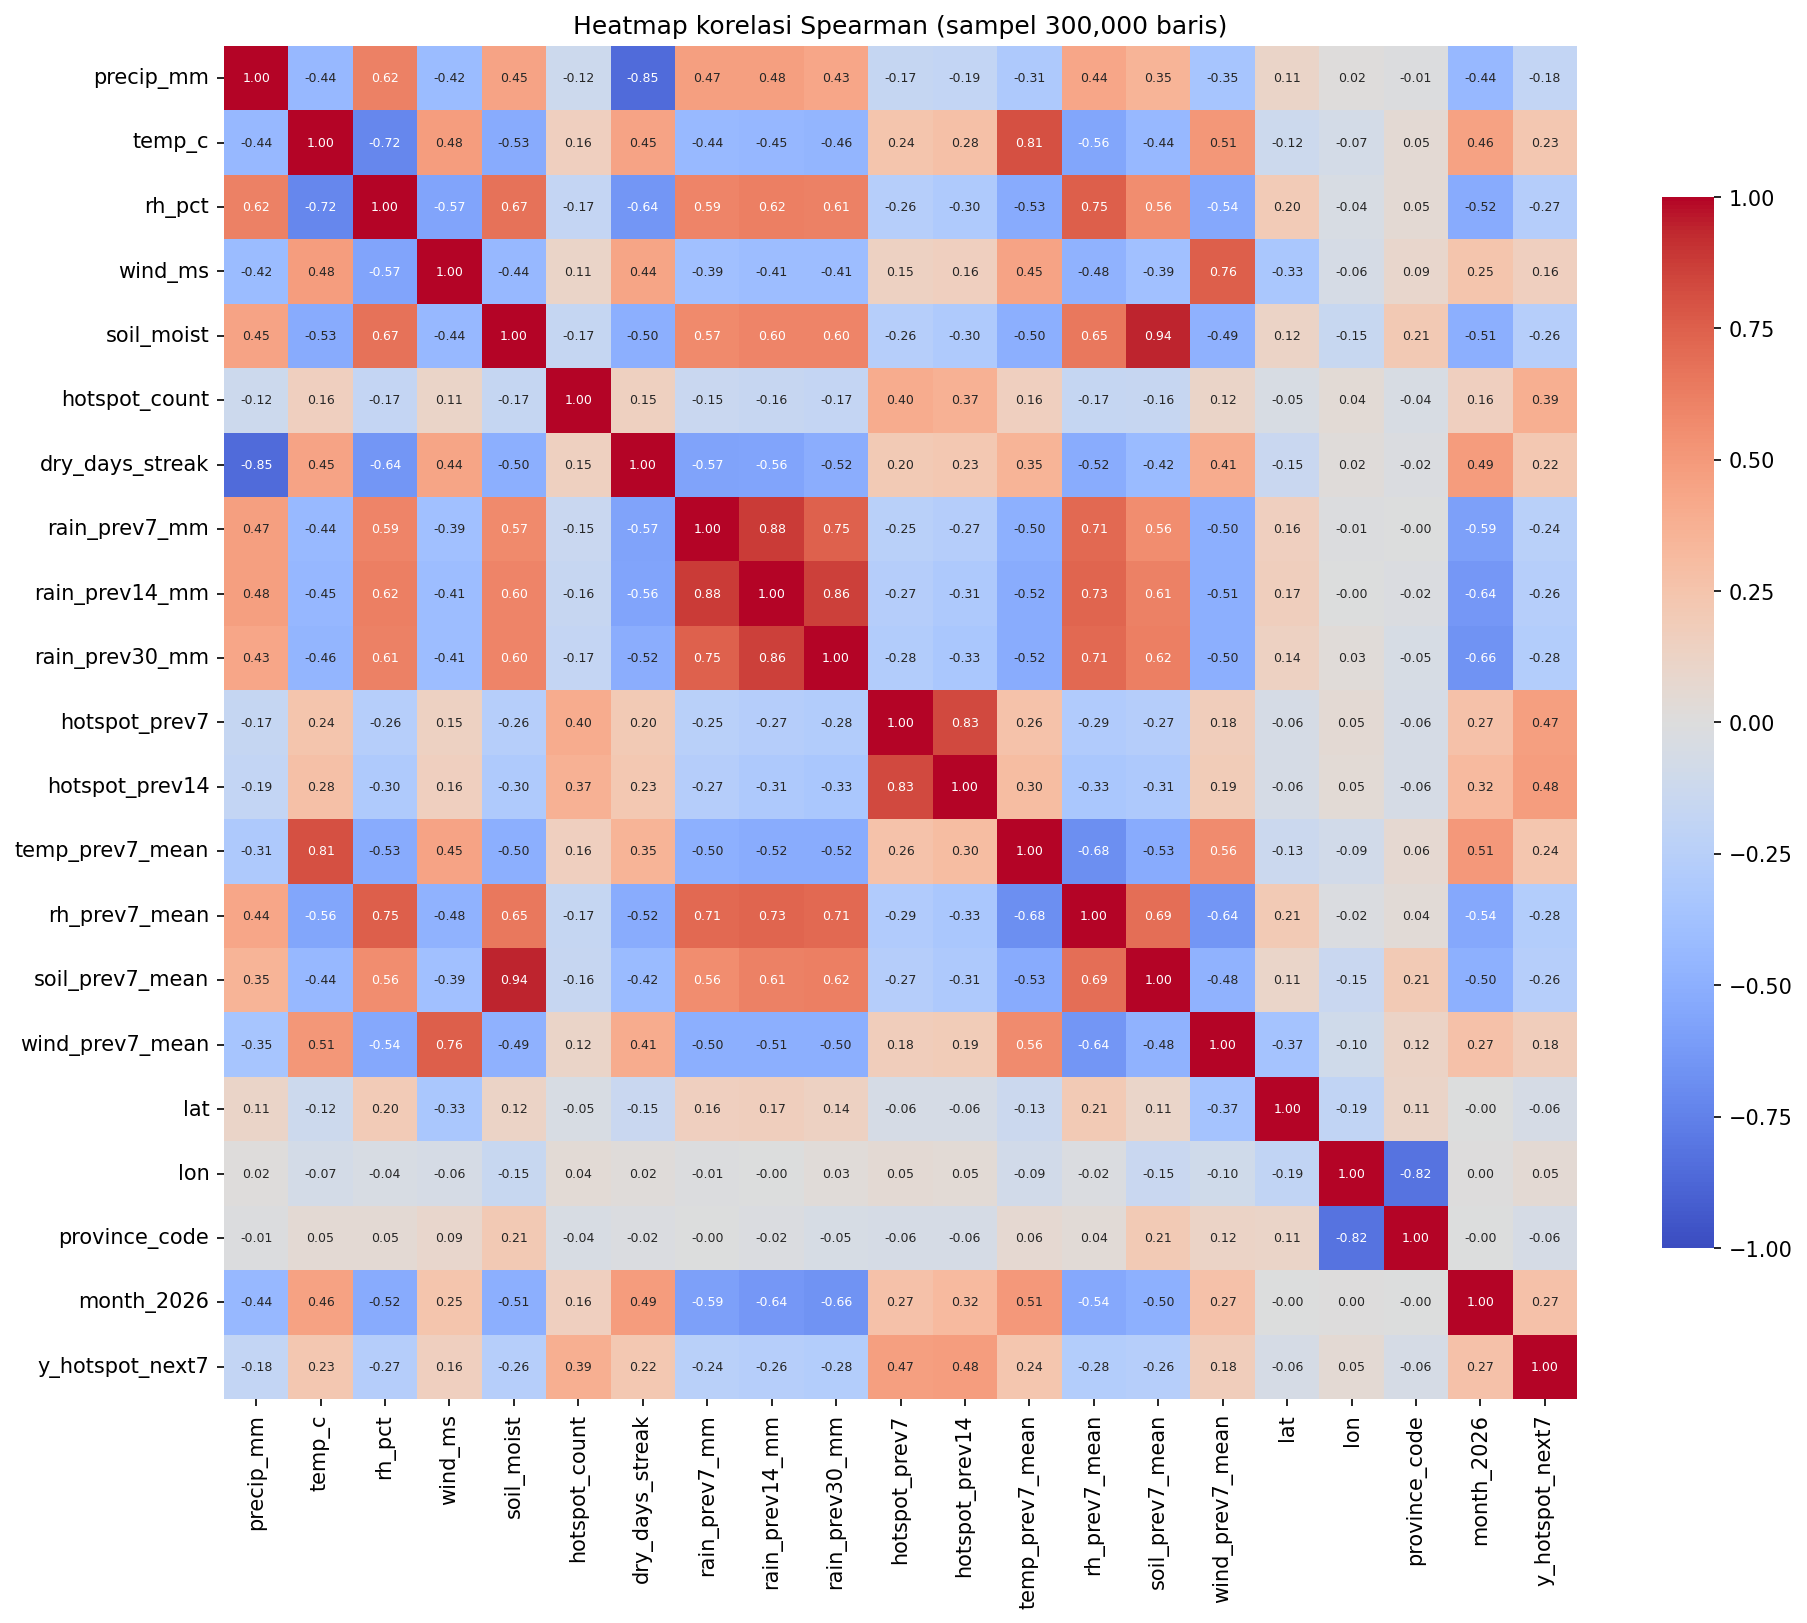

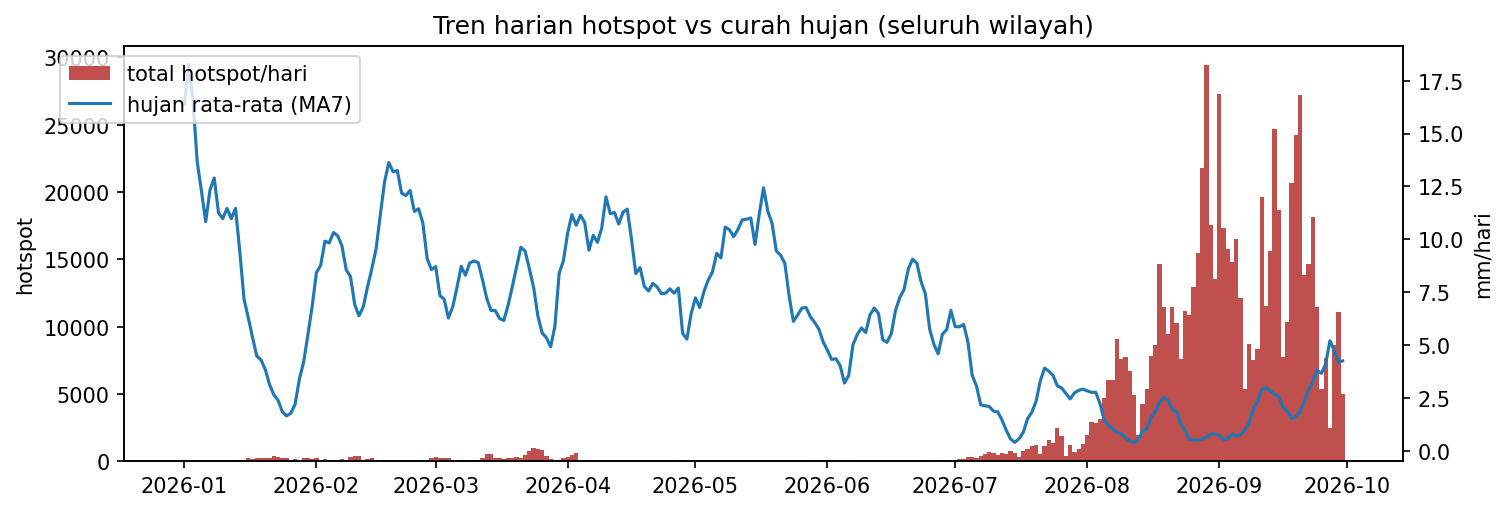

In [16]:
show("heatmap_korelasi_spearman.png"); show("eda_tren_harian.png")

**Interpretasi korelasi:** 

Kami memakai korelasi Spearman (berbasis peringkat) di samping Pearson karena hujan, FRP, dan jumlah hotspot berdistribusi sangat miring dan banyak bernilai nol. Korelasi bukan sebab-akibat.

* **Prediktor terkuat adalah riwayat hotspot:** `hotspot_prev7` (ρ = 0,231), `hotspot_prev14` (0,230), dan `hotspot_count` hari itu (0,204). Artinya lokasi yang baru terbakar cenderung terbakar lagi dalam seminggu ke depan.
* **Variabel cuaca berkorelasi lemah tetapi arahnya sesuai logika fisik:** hujan (`rain_prev7/14/30_mm`), kelembapan relatif, dan kelembapan tanah berkorelasi negatif (sekitar −0,08 sampai −0,10), sedangkan `dry_days_streak` dan suhu berkorelasi positif (0,099 dan 0,070). Semakin kering dan panas, semakin besar peluang hotspot.
* **Seleksi fitur:** dari 21 fitur kandidat, `frp_prev7` dibuang karena redundan dengan `hotspot_prev7` (|ρ| = 1,00); 20 fitur dipertahankan. `lat` hampir tidak informatif (mutual information ≈ 0) tetapi tidak melewati ambang redundansi sehingga tetap dipertahankan.
* Korelasi tiap fitur dengan target tergolong kecil (|ρ| < 0,25), wajar karena kejadian hotspot dipengaruhi banyak faktor sekaligus, bukan satu variabel tunggal.

## Tahap 9 — Clean Dataset
Parquet (utama) + CSV sampel + kamus data + laporan QC + bukti file mentah utuh.

In [17]:
export = s09_export.run(df, feat["selected"], raw, qc)
print(export["final"].shape, "| file mentah utuh:", export["integrity"]["raw_intact"])
display(export["dictionary"])
print((C.P.qc / "qc_ringkasan.md").read_text(encoding="utf-8"))

06:10:17 | [9_export] missing_variabel_cuaca_akhir = 0
06:10:17 | [9_export] duplikasi_cell_date_akhir = 0
06:10:17 | [9_export] baris_akhir = 6156969
06:10:17 | [9_export] kolom_akhir = 39
d:\PROJECT\uas_data_wrangling\scripts\pipeline\s09_export.py:90: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.sample(min(len(g), per_prov), random_state=C.RANDOM_STATE)))["cell_id"]
06:10:43 | [9_export] csv_sample_baris = 81900
06:10:45 | [9_export] file_mentah_utuh = True
06:10:45 | [9_export] file_hasil = ...
06:10:45 | Clean dataset: D:\PROJECT\uas_data_wrangling\data\cleaned\dataset_karhutla_2026_clean.parquet (240.2 MB)


(6156969, 39) | file mentah utuh: True


,kolom,tipe,deskripsi,satuan,sumber,dipakai_model
0,cell_id,object,ID sel grid ~5 km (kunci bersama cell_id+date),-,grid,False
1,date,datetime64[ns],Tanggal pengamatan (YYYY-MM-DD),tanggal,-,False
2,province,object,Provinsi tempat sel berada,-,geoBoundaries / grid,False
3,lat,float64,Lintang pusat sel,derajat,grid,True
4,lon,float64,Bujur pusat sel,derajat,grid,True
5,precip_mm,float32,Curah hujan harian,mm/hari,CHIRPS (via GEE),True
6,temp_c,float32,Suhu udara 2 m (dari Kelvin),°C,ERA5-Land (via GEE),True
7,rh_pct,float32,Kelembapan relatif (dihitung dari suhu & titik...,%,ERA5-Land (turunan),True
8,wind_ms,float32,Kecepatan angin 10 m = sqrt(u^2+v^2),m/s,ERA5-Land (turunan),True
9,soil_moist,float32,Kelembapan tanah lapisan 1,m3/m3,ERA5-Land (via GEE),True


# Ringkasan Quality Control (dibuat otomatis oleh pipeline)

Mode: **real**  |  Waktu proses: 406 detik

## Sebelum vs sesudah
| Tahap | Indikator | Nilai |
|---|---|---|
| Ingestion | baris FIRMS mentah | 2613261 |
| Ingestion | baris CHIRPS / ERA5 mentah | 6156969 / 6156969 |
| Cleaning FIRMS | tanggal non-ISO diperbaiki | 0 |
| Cleaning FIRMS | koordinat tak valid dibuang | 0 |
| Cleaning FIRMS | duplikat deteksi dibuang | 0 |
| Cleaning FIRMS | baris akhir | 817096 |
| Cleaning cuaca | duplikat persis dibuang (CHIRPS) | 0 |
| Cleaning cuaca | nilai di luar domain -> NaN | {'temp_c': 0, 'dewpoint_c': 0, 'wind_ms': 0, 'soil_moist': 0, 'precip_mm': 0} |
| Missing | strategi imputasi terpilih | ffill_cell |
| Missing | nilai diimputasi | 307944 |
| Integrasi | baris sebelum / sesudah join | 6156969 / 6156969 |
| Integrasi | duplikasi cell_id+date | 0 |
| Outlier | anomali multivariat (IsoForest) | 30828 |
| Fitur | proporsi kelas positif target | 0.0652 |
| Akhir | baris x kolom | 6156

## Tahap 10 — Analisis Lanjutan: Klasifikasi Biner
Split **temporal** (train Jan–Jul, validasi Agustus, uji September) dengan jeda 7 hari. LightGBM vs Logistic Regression vs baseline prevalensi.
Ini **pembuktian kesiapan data**, bukan tujuan utama. PR-AUC 0,5533 / F1 0,5363 pada DIMAS-TI adalah *rujukan*, bukan hasil baru.

In [18]:
model = s10_classification.run(df, feat["selected"], qc)
pd.DataFrame({k: {m: v for m, v in r.items() if m in ("pr_auc", "precision", "recall", "f1", "threshold")}
              for k, r in model.items() if k != "info"}).T.round(4)

06:10:47 | [10_classification] split = ...
06:11:41 | gambar disimpan: klasifikasi_pr_curve.png
06:11:41 | gambar disimpan: klasifikasi_confusion_matrix.png
06:11:42 | gambar disimpan: klasifikasi_feature_importance.png
06:11:42 | [10_classification] metrik_uji = ...


,pr_auc,precision,recall,f1,threshold
baseline_prevalensi,0.2013,0.2013,1.0000,0.3351,0.0000
logreg_scaled,0.6292,0.4453,0.7441,0.5572,0.9597
lightgbm,0.6587,0.4870,0.7280,0.5836,0.1636


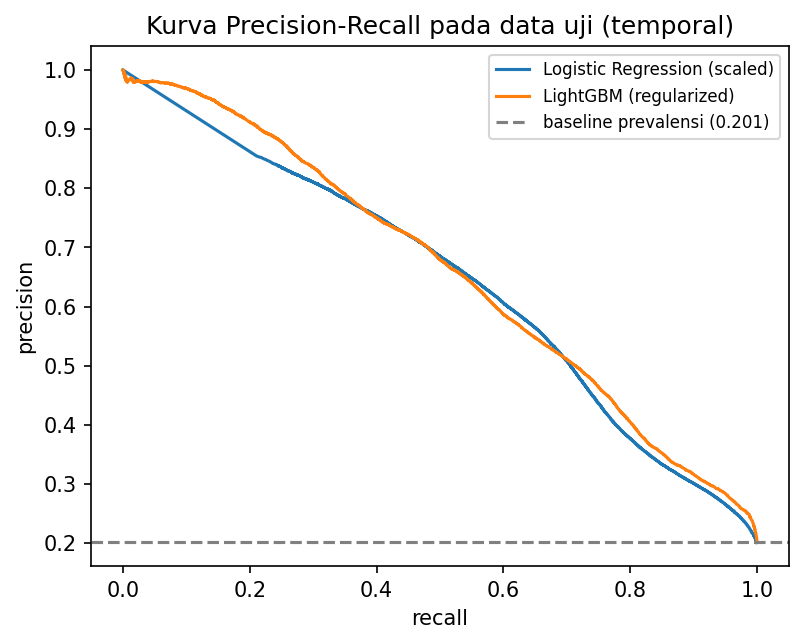

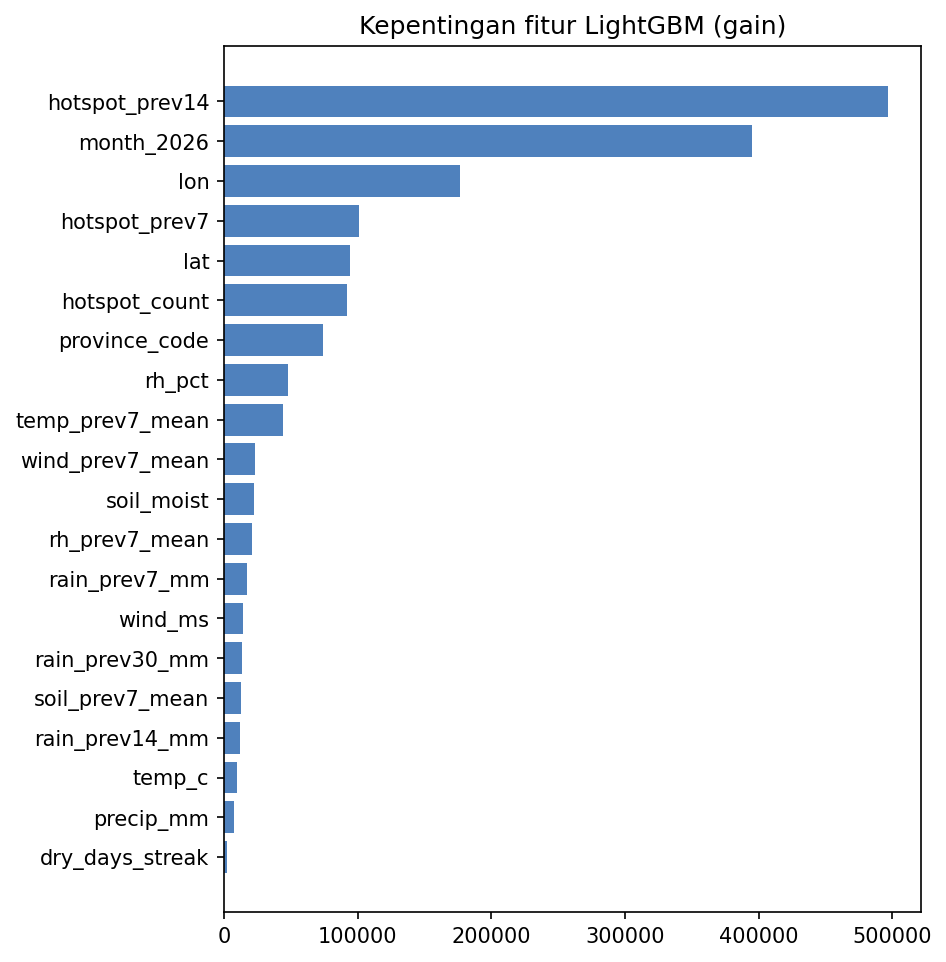

In [19]:
show("klasifikasi_pr_curve.png"); show("klasifikasi_feature_importance.png")

**Interpretasi:** 

Klasifikasi biner (ada hotspot dalam 7 hari ke depan) dipakai sebagai bukti bahwa dataset hasil wrangling layak dipakai pemodelan, bukan sebagai tujuan utama. Pembagian data bersifat temporal dengan jeda 7 hari: latih sampai 24 Juli, validasi 1–24 Agustus, uji 1–23 September 2026.

| Model | PR-AUC | F1 | Recall | Precision |
|---|---|---|---|---|
| Baseline prevalensi | 0,201 | 0,335 | 1,000 | 0,201 |
| Logistic Regression (scaled) | 0,629 | 0,557 | 0,744 | 0,445 |
| **LightGBM** | **0,659** | **0,584** | 0,728 | 0,487 |

LightGBM mencapai PR-AUC sekitar 3,3 kali baseline dan sedikit mengungguli Logistic Regression (ROC-AUC 0,846 vs 0,834), sehingga fitur hasil wrangling memuat sinyal yang berguna. Kami memakai PR-AUC, bukan akurasi, karena kelas positif jarang. Ambang klasifikasi dipilih dari data validasi, bukan dari data uji.

**Keterbatasan:** 

(1) prevalensi positif data latih hanya 1,8% sedangkan data uji 20,1% karena September adalah puncak musim kebakaran, sehingga ada pergeseran distribusi dan ambang dari validasi tidak optimal untuk uji; 

(2) riwayat hotspot adalah prediktor dominan sehingga model sebagian besar mengandalkan pola "lokasi yang baru terbakar akan terbakar lagi"; 

(3) angka ini tidak dibandingkan langsung dengan hasil penelitian DIMAS-TI (PR-AUC 0,5533) karena periode dan pembagian datanya berbeda.

In [20]:
print("QC tersimpan:", qc.save())

QC tersimpan: D:\PROJECT\uas_data_wrangling\outputs\quality_control\qc_report.json
